# 02 · Results analysis

Deep dive into one benchmark run. Set `RUN_DIR` to a specific folder under `results/live/` to pin it; by default the
most recent run is used. Every chart is computed from `predictions.jsonl`, so it can be checked against `report.md`.

In [1]:
%matplotlib inline
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from nbutil import *
style()
pd.set_option("display.precision", 3)

from triage.schema import TYPOLOGIES
RUN_DIR = latest_run()
report = json.loads((RUN_DIR / "report.json").read_text())
rows = load_jsonl(RUN_DIR / "predictions.jsonl")
meta = report["meta"]
MODELS = [m for m in ["jev", "gpt-4o-mini", "reference_model", "rules"] if m in rows[0]]
API = [m for m in MODELS if m in ("jev", "gpt-4o-mini")]
PROB = [m for m in MODELS if m != "rules"]
print(RUN_DIR.relative_to(ROOT), "| mode:", meta["mode"], "| publishable:", meta["publishable"], "| n:", meta["dataset"]["n"])
if not meta["publishable"]:
    print("WARNING: dry-run or stand-in data. Numbers below are for plumbing only.")
truth = np.array([r["label"]["typology"] for r in rows])
def pred(m): return np.array([r[m]["predicted"] if r[m]["ok"] else "ERROR" for r in rows])
def p_pred(m): return np.array([r[m]["probs"].get(r[m]["predicted"], 0) if r[m]["ok"] else 0 for r in rows])

results/live/sequential | mode: live | publishable: True | n: 150


## Headline

In [2]:
print((RUN_DIR / "report.md").read_text().split("## F1 per typology")[0])

# Fraud alert triage: Jev vs GPT-4o-mini

| Run |  |
| --- | --- |
| Timestamp (UTC) | 2026-11-08T18:00:07+00:00 |
| Dataset | `data/alerts_test.jsonl` · n=150 · sha256 `3482e6c42ec4` · paysim |
| Criteria sha256 | `3ef0b060f246` |
| Models served | jev: jev-1.14.0; gpt-4o-mini: gpt-4o-mini-2024-07-18 |
| Concurrency / model | 1 |
| Client region | unspecified |
| Git | `none` |

## Headline (settle when p(predicted class) ≥ 0.85)

| Metric | Jev | GPT-4o-mini | Supervised ref. (ceiling) | Analyst rules (floor) |
| --- | ---: | ---: | ---: | ---: |
| Macro F1 [95% CI] | 0.824 [0.760, 0.879] | 0.286 [0.203, 0.367] | 0.955 [0.921, 0.982] | 0.832 [0.768, 0.885] |
| Accuracy | 81.3% | 28.7% | 94.7% | 82.7% |
| Settled automatically | 59/150 (39.3%) | 114/150 (76.0%) | 132/150 (88.0%) | – |
| Accuracy of settled | 98.3% | 23.7% | 99.2% | – |
| Fraud auto-cleared as NORMAL | 0 | 0 | 0 | – |
| P50 / P90 / P99 latency (ms) | 306 / **409** / 987 | 991 / **1440** / 1781 | – | – |
| P90 95% CI (m

## Confusion matrices (rows = truth)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


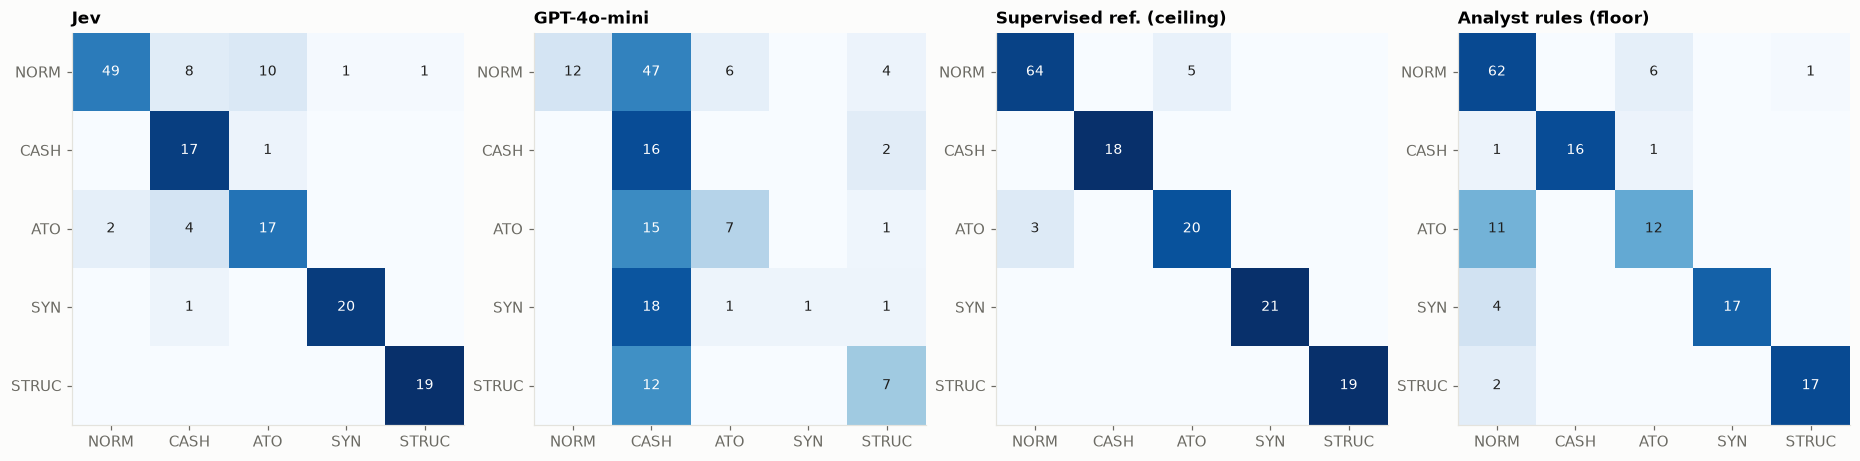

In [3]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 4), constrained_layout=True)
short = ["NORM", "CASH", "ATO", "SYN", "STRUC"]
for ax, m in zip(np.atleast_1d(axes), MODELS):
    cm = pd.crosstab(pd.Categorical(truth, TYPOLOGIES), pd.Categorical(pred(m), TYPOLOGIES + ["ERROR"]), dropna=False)
    cm = cm.loc[TYPOLOGIES, TYPOLOGIES].values
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                        color="white" if norm[i, j] > 0.55 else INK)
    ax.set_xticks(range(5), short); ax.set_yticks(range(5), short); ax.grid(False)
    ax.set_title(MODEL_TITLES[m], loc="left")
plt.show()

## Calibration

Reliability diagram on the predicted class: of alerts predicted with probability ≈ p, how many were right?
Points on the diagonal are well calibrated; points below it are overconfident. Marker size shows how many alerts fall in the bin.

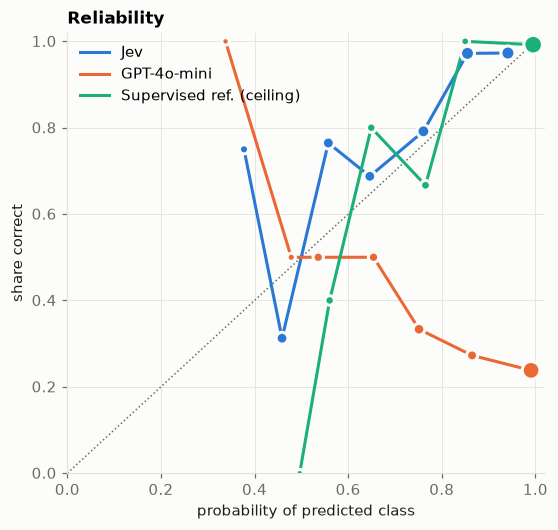

,Jev,GPT-4o-mini,Supervised ref. (ceiling)
brier,0.28,1.343,0.066
log_loss,0.576,6.923,0.106
ece_top_label,0.094,0.627,0.023


In [4]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle=":")
edges = np.linspace(0, 1, 11)
for m in PROB:
    conf, correct = p_pred(m), (pred(m) == truth)
    xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi) if lo > 0 else (conf >= lo) & (conf <= hi)
        if mask.sum():
            xs.append(conf[mask].mean()); ys.append(correct[mask].mean()); ns.append(mask.sum())
    ax.plot(xs, ys, color=MODEL_COLORS[m], marker="o", markersize=0, label=MODEL_TITLES[m])
    ax.scatter(xs, ys, s=[12 + 3 * np.sqrt(n) * 4 for n in ns], color=MODEL_COLORS[m], edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.set_xlabel("probability of predicted class"); ax.set_ylabel("share correct"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left"); ax.set_title("Reliability", loc="left")
plt.show()
pd.DataFrame({MODEL_TITLES[m]: report["models"][m]["calibration"] for m in PROB}).loc[["brier", "log_loss", "ece_top_label"]]

## Settlement: how much can be cleared automatically, and at what cost?

Each curve sweeps the threshold τ on the predicted-class probability. Moving left means settling more alerts
automatically; the y-axis shows how many of those were right. The marked point is τ = 0.85.

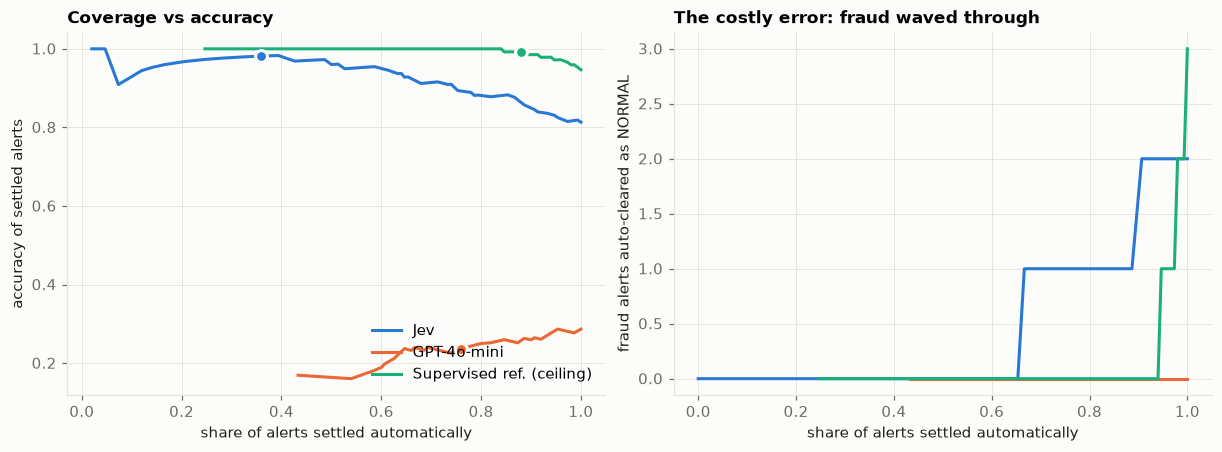

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
taus = np.linspace(0.3, 0.999, 120)
for m in PROB:
    conf, correct = p_pred(m), (pred(m) == truth)
    is_fraud_cleared = (pred(m) == "NORMAL") & (truth != "NORMAL")
    cov = [(conf >= t).mean() for t in taus]
    acc = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in taus]
    missed = [is_fraud_cleared[conf >= t].sum() for t in taus]
    axes[0].plot(cov, acc, color=MODEL_COLORS[m], label=MODEL_TITLES[m])
    k = np.argmin(np.abs(taus - 0.85))
    axes[0].scatter([cov[k]], [acc[k]], color=MODEL_COLORS[m], s=60, edgecolor="#fcfcfb", linewidth=2, zorder=3)
    axes[1].plot(cov, missed, color=MODEL_COLORS[m], label=MODEL_TITLES[m])
axes[0].set_xlabel("share of alerts settled automatically"); axes[0].set_ylabel("accuracy of settled alerts")
axes[0].set_title("Coverage vs accuracy", loc="left"); axes[0].legend(loc="lower right")
axes[1].set_xlabel("share of alerts settled automatically"); axes[1].set_ylabel("fraud alerts auto-cleared as NORMAL")
axes[1].set_title("The costly error: fraud waved through", loc="left")
plt.show()

## Latency

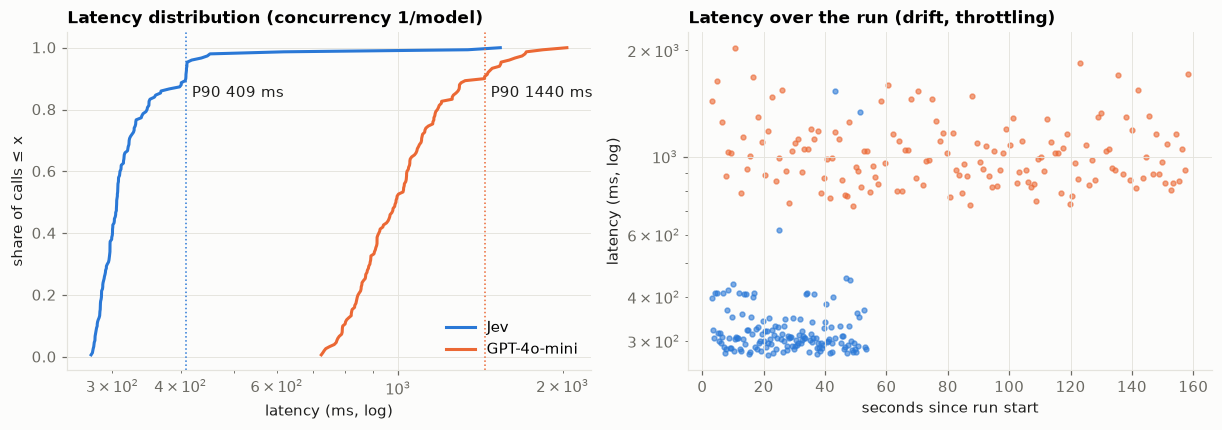

,n,p50_ms,p90_ms,p90_ci95_ms,p99_ms,max_ms,mean_ms,e2e_p90_ms,retried_calls
Jev,150,305.528,408.751,"[360.024, 410.629]",987.405,1538.257,335.249,408.824,0
GPT-4o-mini,150,991.235,1439.721,"[1262.298, 1533.64]",1780.622,2036.463,1044.425,1440.124,0


In [6]:
if API:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
    for m in API:
        lat = np.sort([r[m]["latency_ms"] for r in rows if r[m]["ok"]])
        axes[0].plot(lat, np.arange(1, len(lat) + 1) / len(lat), color=MODEL_COLORS[m], label=MODEL_TITLES[m])
        p90 = np.percentile(lat, 90)
        axes[0].axvline(p90, color=MODEL_COLORS[m], linewidth=1, linestyle=":")
        axes[0].annotate(f"P90 {p90:.0f} ms", (p90, 0.9), textcoords="offset points", xytext=(4, -12), color=INK)
        t = [r[m]["started_at_s"] for r in rows if r[m]["ok"]]
        l = [r[m]["latency_ms"] for r in rows if r[m]["ok"]]
        axes[1].scatter(t, l, s=10, color=MODEL_COLORS[m], alpha=0.6, label=MODEL_TITLES[m])
    axes[0].set_xscale("log"); axes[0].set_xlabel("latency (ms, log)"); axes[0].set_ylabel("share of calls ≤ x")
    axes[0].set_title(f"Latency distribution (concurrency {meta['concurrency_per_model']}/model)", loc="left")
    axes[0].legend(loc="lower right")
    axes[1].set_yscale("log"); axes[1].set_xlabel("seconds since run start"); axes[1].set_ylabel("latency (ms, log)")
    axes[1].set_title("Latency over the run (drift, throttling)", loc="left")
    plt.show()
    display(pd.DataFrame({MODEL_TITLES[m]: report["models"][m]["latency"] for m in API}).T)

## Accuracy by scenario

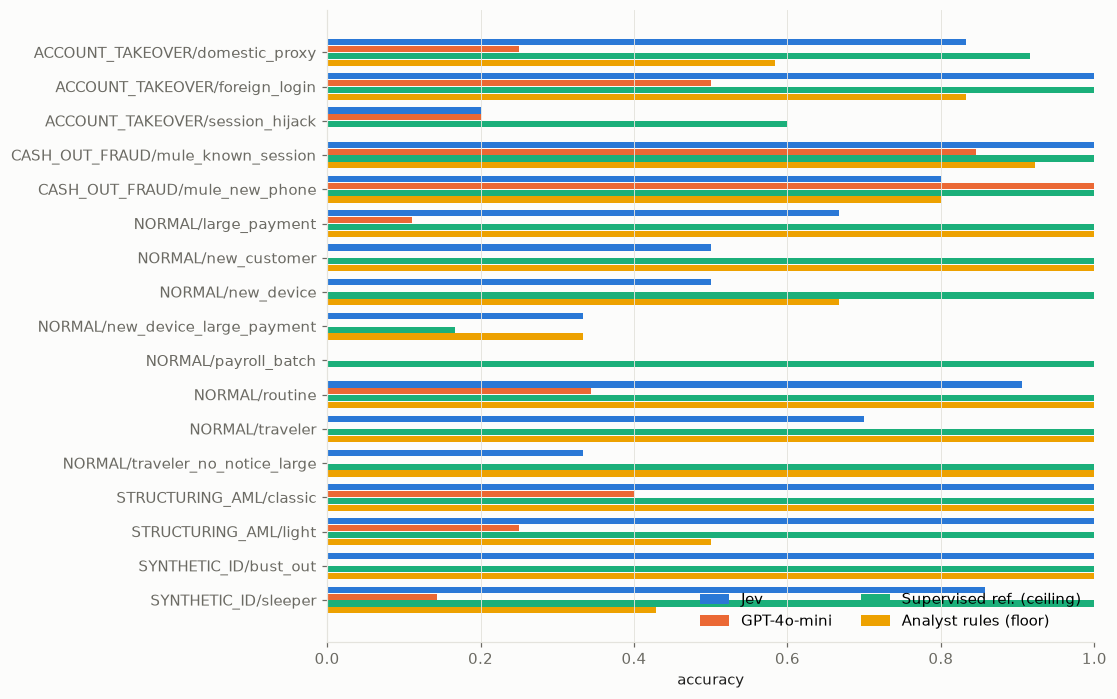

,n,Jev,GPT-4o-mini,Supervised ref. (ceiling),Analyst rules (floor)
ACCOUNT_TAKEOVER/domestic_proxy,12,0.833,0.250,0.917,0.583
ACCOUNT_TAKEOVER/foreign_login,6,1.000,0.500,1.000,0.833
ACCOUNT_TAKEOVER/session_hijack,5,0.200,0.200,0.600,0.000
CASH_OUT_FRAUD/mule_known_session,13,1.000,0.846,1.000,0.923
CASH_OUT_FRAUD/mule_new_phone,5,0.800,1.000,1.000,0.800
NORMAL/large_payment,9,0.667,0.111,1.000,1.000
NORMAL/new_customer,2,0.500,0.000,1.000,1.000
NORMAL/new_device,6,0.500,0.000,1.000,0.667
NORMAL/new_device_large_payment,6,0.333,0.000,0.167,0.333
NORMAL/payroll_batch,1,0.000,0.000,1.000,0.000


In [7]:
scen = sorted({r["label"]["scenario"] for r in rows})
acc = pd.DataFrame({MODEL_TITLES[m]: [np.mean([(r[m]["ok"] and r[m]["predicted"] == r["label"]["typology"])
                                              for r in rows if r["label"]["scenario"] == s]) for s in scen] for m in MODELS},
                   index=scen)
acc.insert(0, "n", [sum(r["label"]["scenario"] == s for r in rows) for s in scen])
fig, ax = plt.subplots(figsize=(9, 0.38 * len(scen) + 1))
h = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    ax.barh(np.arange(len(scen)) + i * h, acc[MODEL_TITLES[m]], height=h - 0.02, color=MODEL_COLORS[m], label=MODEL_TITLES[m])
ax.set_yticks(np.arange(len(scen)) + 0.4 - h / 2, scen); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel("accuracy"); ax.legend(loc="lower right", ncol=2); ax.grid(axis="y", visible=False)
plt.show()
acc

## Hold / release gate

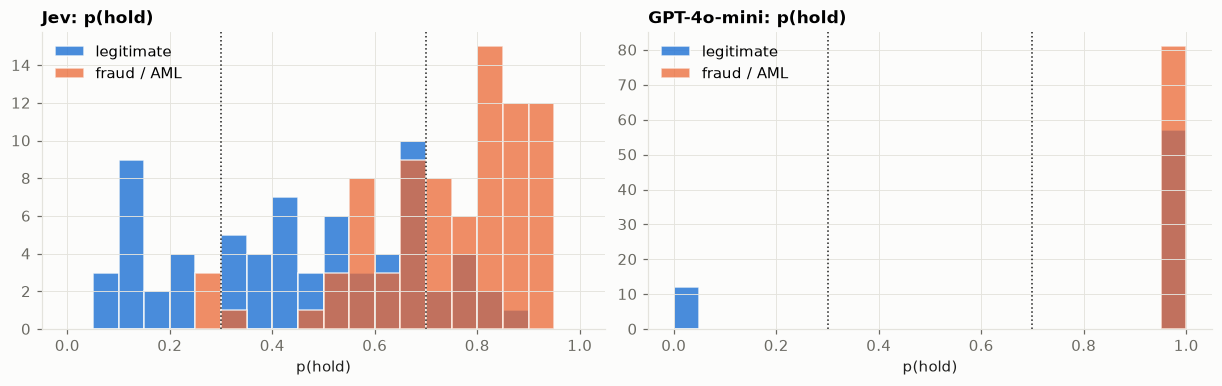

,Jev,GPT-4o-mini
auc,0.853,0.711
brier,0.167,0.38
accuracy_at_0_5,0.753,0.62
band,"{'release_le': 0.3, 'hold_ge': 0.7}","{'release_le': 0.3, 'hold_ge': 0.7}"
released,21,12
held,67,138
sent_to_review,62,0
fraud_released,3,0
legit_held,11,57


In [8]:
if API:
    fig, axes = plt.subplots(1, len(API), figsize=(5.5 * len(API), 3.4), constrained_layout=True, squeeze=False)
    hold_truth = np.array([r["label"]["hold"] for r in rows])
    for ax, m in zip(axes[0], API):
        hp = np.array([r[m]["hold_prob"] if r[m]["ok"] else np.nan for r in rows])
        bins = np.linspace(0, 1, 21)
        ax.hist(hp[~hold_truth], bins=bins, color=MODEL_COLORS["jev"], alpha=0.85, label="legitimate", edgecolor="#fcfcfb")
        ax.hist(hp[hold_truth], bins=bins, color=MODEL_COLORS["gpt-4o-mini"], alpha=0.75, label="fraud / AML", edgecolor="#fcfcfb")
        for x in (0.3, 0.7): ax.axvline(x, color=INK, linewidth=1, linestyle=":")
        ax.set_title(f"{MODEL_TITLES[m]}: p(hold)", loc="left"); ax.set_xlabel("p(hold)"); ax.legend()
    plt.show()
    display(pd.DataFrame({MODEL_TITLES[m]: report["models"][m]["hold_gate"] for m in API}))

## Where Jev and GPT-4o-mini disagree

In [9]:
if set(API) == {"jev", "gpt-4o-mini"}:
    dis = [{"alert": r["alert_id"], "scenario": r["label"]["scenario"], "truth": r["label"]["typology"],
            "jev": pred("jev")[i], "p_jev": round(p_pred("jev")[i], 2),
            "gpt": pred("gpt-4o-mini")[i], "p_gpt": round(p_pred("gpt-4o-mini")[i], 2),
            "ref_p_true": round(r["reference_p_true"], 2) if r["reference_p_true"] is not None else None}
           for i, r in enumerate(rows) if pred("jev")[i] != pred("gpt-4o-mini")[i]]
    dis = pd.DataFrame(dis)
    print(f"{len(dis)} disagreements; Jev right on {(dis.jev == dis.truth).sum()}, GPT right on {(dis.gpt == dis.truth).sum()}")
    display(dis.head(40))

93 disagreements; Jev right on 80, GPT right on 1


,alert,scenario,truth,jev,p_jev,gpt,p_gpt,ref_p_true
0,TEST-00001,SYNTHETIC_ID/sleeper,SYNTHETIC_ID,SYNTHETIC_ID,0.48,CASH_OUT_FRAUD,0.51,0.99
1,TEST-00002,NORMAL/new_device_large_payment,NORMAL,ACCOUNT_TAKEOVER,0.80,CASH_OUT_FRAUD,1.00,0.17
2,TEST-00003,NORMAL/routine,NORMAL,NORMAL,0.91,CASH_OUT_FRAUD,0.90,1.00
3,TEST-00005,SYNTHETIC_ID/sleeper,SYNTHETIC_ID,SYNTHETIC_ID,0.69,CASH_OUT_FRAUD,1.00,0.99
4,TEST-00006,ACCOUNT_TAKEOVER/domestic_proxy,ACCOUNT_TAKEOVER,ACCOUNT_TAKEOVER,0.85,CASH_OUT_FRAUD,1.00,1.00
5,TEST-00007,NORMAL/routine,NORMAL,NORMAL,0.95,CASH_OUT_FRAUD,1.00,1.00
6,TEST-00010,ACCOUNT_TAKEOVER/domestic_proxy,ACCOUNT_TAKEOVER,NORMAL,0.68,CASH_OUT_FRAUD,0.87,0.53
7,TEST-00011,SYNTHETIC_ID/sleeper,SYNTHETIC_ID,SYNTHETIC_ID,0.65,ACCOUNT_TAKEOVER,0.52,1.00
8,TEST-00013,NORMAL/new_device_large_payment,NORMAL,NORMAL,0.41,CASH_OUT_FRAUD,1.00,0.49
9,TEST-00016,CASH_OUT_FRAUD/mule_new_phone,CASH_OUT_FRAUD,ACCOUNT_TAKEOVER,0.45,CASH_OUT_FRAUD,1.00,1.00


## Jev's confident mistakes (p ≥ 0.85)

In [10]:
if "jev" in API:
    test = {a["alert_id"]: a for a in load_jsonl(ROOT / meta["dataset"]["path"])}
    bad = [r for i, r in enumerate(rows) if pred("jev")[i] != truth[i] and p_pred("jev")[i] >= 0.85]
    out = []
    for r in bad:
        s = test[r["alert_id"]]["signals"]; t = test[r["alert_id"]]["transaction"]
        out.append({"alert": r["alert_id"], "scenario": r["label"]["scenario"], "jev": r["jev"]["predicted"],
                    "p": round(r["jev"]["probs"][r["jev"]["predicted"]], 2), "ref_p_true": r["reference_p_true"],
                    "drain": round(t["amount"] / t["oldbalanceOrg"], 2) if t["oldbalanceOrg"] else None,
                    "known_dev": s["is_known_device"], "risk": s["device_risk_score"],
                    "cred_h": s["hours_since_credential_change"], "fails": s["failed_login_attempts_24h"],
                    "fund_h": s["hours_since_inbound_funding"], "ip": s["ip_location"], "travel": s["travel_notice_active"]})
    display(pd.DataFrame(out))

,alert,scenario,jev,p,ref_p_true,drain,known_dev,risk,cred_h,fails,fund_h,ip,travel
0,TEST-00130,NORMAL/payroll_batch,STRUCTURING_AML,0.96,0.858,0.3,True,0.03,5377.4,1,64.5,"New York, NY",False
